
# Predictive Customer Churn Classifier
### Customer Churn Prediction Using Random Forest and XGBoost

**Objective:**
The objective of this project is to develop machine learning classification models to predict whether a telecom customer is likely to leave the company's services (churn) or continue using them.

**Dataset:** Telco Customer Churn Dataset

**Machine Learning Models:**
- Random Forest Classifier
- XGBoost Classifier

**Key Techniques:**
- Data Cleaning and Preprocessing
- One-Hot Encoding
- Handling Class Imbalance (SMOTE / Class Weighting)
- Stratified Cross-Validation
- ROC Curve and ROC-AUC Evaluation
- Feature Importance Analysis

**Evaluation Metrics:**
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC Score



## 1. Importing Libraries
In this section, we import the essential Python libraries required for data manipulation, numerical operations, and data visualization.

In [143]:
# Importing essential libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


## 2. Loading the Dataset
The Telco Customer Churn dataset is loaded into a Pandas DataFrame for further analysis and preprocessing.

In [144]:
# Load the dataset
df = pd.read_csv(" Telco_Customer_Churn.csv")

## 3. Initial Data Inspection
In this section, we examine the dataset structure, dimensions, data types, and statistical summary to understand the available customer information.

In [145]:
# Display the first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [146]:
# Check number of rows and columns
df.shape

(7043, 21)

In [147]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [148]:
# Statistical summary of numerical columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## 4. Data Quality Assessment
This section focuses on identifying missing values, duplicate records, and understanding the available features before preprocessing.

In [149]:
# Check missing values in each column
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [150]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [151]:
# Display all column names
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

## 5. Target Variable Analysis
The target variable `Churn` indicates whether a customer has discontinued the telecom service.

In this section, we analyze the distribution of customers who stayed and those who left the service. This helps us understand whether the dataset has a class imbalance problem.

In [152]:
# Check distribution of target variable
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [153]:
# Calculate percentage distribution
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

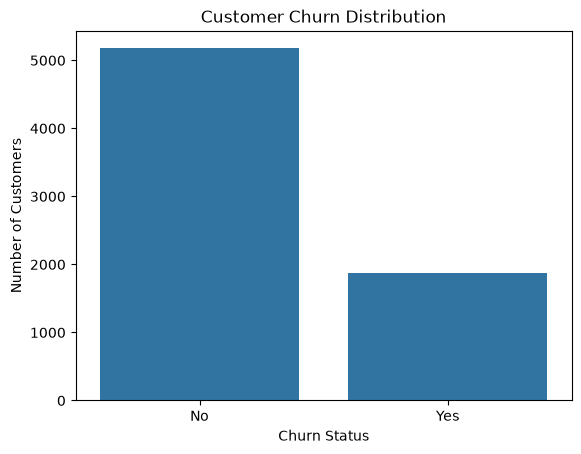

In [154]:
# Visualize the distribution of churn customers
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.show()

### Observation
The dataset contains 7,043 customer records.
- 5,174 customers (73.46%) did not churn.
- 1,869 customers (26.54%) churned.

The target variable shows an imbalance between the two classes, as the number of non-churn customers is significantly higher than the number of churn customers.

Therefore, class imbalance handling techniques such as SMOTE or class weighting will be considered during model development.

## 6. Data Cleaning and Preprocessing
In this section, we examine the data types of different features and prepare the dataset for machine learning. Special attention is given to converting numerical columns into appropriate data types and handling any missing values identified during preprocessing.

In [155]:
# Check the data types of all columns
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

### 6.1 Handling TotalCharges Column
The `TotalCharges` feature represents the total amount charged to a customer over their subscription period.

Although it contains numerical values, it is stored as an object data type. We will inspect this column and convert it into a numeric format for machine learning.

In [156]:
# Check the TotalCharges column data type
df["TotalCharges"].dtype

<StringDtype(storage='python', na_value=nan)>

In [157]:
# Identify blank or whitespace-only values
(df["TotalCharges"].astype(str).str.strip() == "").sum()

np.int64(11)

### 6.2 Converting TotalCharges to Numeric
The blank values in `TotalCharges` need to be handled before numerical conversion. We use `pd.to_numeric()` with `errors="coerce"` to convert valid values into numbers and invalid or blank values into NaN.

In [158]:
# Convert TotalCharges into numeric format, coercing errors to NaN for non-numeric values
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
# Check the updated data type
df["TotalCharges"].dtype

dtype('float64')

### 6.3 Handling Missing Values
After converting `TotalCharges` into a numeric format, any blank or invalid entries are represented as missing values (NaN).
We will identify these missing values before deciding how to handle them.

In [159]:
# Check missing values in TotalCharges
df["TotalCharges"].isnull().sum()

np.int64(11)

In [160]:
# Display rows where TotalCharges is missing
df[df["TotalCharges"].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


### Observation
The conversion of `TotalCharges` into numeric format revealed missing values in the column. These values need to be handled before model training to ensure proper numerical processing.

### 6.4 Imputing Missing Values
Missing values in `TotalCharges` need to be handled before training machine learning models.
We will use median imputation to replace missing values. The median is less sensitive to extreme values compared to the mean.

In [161]:
# Calculate the median of TotalCharges
median_total_charges = df["TotalCharges"].median()
median_total_charges

np.float64(1397.475)

In [162]:
# Replace missing values with the median
df["TotalCharges"] = df["TotalCharges"].fillna(median_total_charges)

In [163]:
# Check missing values after imputation
df["TotalCharges"].isnull().sum()

np.int64(0)


**Observation:** Missing values in `TotalCharges` were replaced using median imputation. This ensures that the column contains valid numerical values for further analysis.

## 7. Feature Type Identification
The dataset contains both numerical and categorical features.
Numerical features represent measurable quantities, while categorical features represent groups or labels.
Identifying these feature types is important because different preprocessing techniques are required for each type of data.

In [164]:
# Select numerical columns
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns
numerical_cols

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')

In [165]:
# Select categorical columns
categorical_cols = df.select_dtypes(include=["object", "string"]).columns
categorical_cols

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')

In [166]:
# Count numerical and categorical features
print("Number of Numerical Features:", len(numerical_cols))
print("Number of Categorical Features:", len(categorical_cols))

Number of Numerical Features: 4
Number of Categorical Features: 17


### Observation
The dataset contains a combination of numerical and categorical features. Numerical features will require appropriate scaling, while categorical features will be transformed using One-Hot Encoding during model preprocessing.

## 8. Removing Irrelevant Features

The `customerID` column contains unique identification numbers for each customer. Since it does not provide meaningful information about customer behaviour or churn patterns, it will be excluded from the model features.

In [167]:
# Check the first five customer IDs
df["customerID"].head()

0    7590-VHVEG
1    5575-GNVDE
2    3668-QPYBK
3    7795-CFOCW
4    9237-HQITU
Name: customerID, dtype: str

In [168]:
# Count unique customer IDs
df["customerID"].nunique()

7043

In [169]:
# Remove customerID from the dataset as it is not relevant for analysis
df = df.drop("customerID", axis=1)
# Check remaining columns
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

### Observation
The `customerID` column was removed because it serves only as a unique identifier and does not contribute meaningful predictive information. The remaining features will be used for further analysis and model development.

## 9. Feature Selection
Feature selection involves identifying the input variables and the target variable required for machine learning.

In this project, the `Churn` column will be used as the target variable, while all remaining relevant columns will be used as input features.

In [170]:
# Separate input features and target variable
X = df.drop("Churn", axis=1)
y = df["Churn"].map({"No": 0, "Yes": 1})

In [171]:
# Check dimensions of features and target
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [172]:
# Display unique target values
y.unique()

array([0, 1])

In [173]:
# Check the unique values in the target variable
y.value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

## 10. Train-Test Split
The dataset is divided into training and testing sets.

- The training set (80%) is used to train the machine learning models.
- The testing set (20%) is used to evaluate model performance on unseen data.

Stratified sampling is applied to maintain the original class distribution of the target variable in both sets.

In [174]:
from sklearn.model_selection import train_test_split
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [175]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


## 12. Identifying Numerical and Categorical Features
The input features are divided into numerical and categorical variables.
- Numerical features contain measurable values.
- Categorical features represent groups or categories.

This identification helps apply suitable preprocessing techniques to each feature type.

In [176]:
# Identify numerical and categorical columns from training data
numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print("Numerical Features:", numerical_cols)
print("\nCategorical Features:", categorical_cols)

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 13. Data Preprocessing
Data preprocessing prepares the input features for machine learning models.

In this project:
- Missing numerical values will be handled using median imputation.
- Missing categorical values will be handled using the most frequent value.
- Categorical features will be converted into numerical format using One-Hot Encoding.

A ColumnTransformer will be used to apply these preprocessing steps separately to numerical and categorical features.

In [177]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [178]:
# Create a pipeline for numerical features
numerical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median"))])

In [179]:
# Create a pipeline for categorical features

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

## 14. Combining Preprocessing Steps Using ColumnTransformer

The ColumnTransformer combines the numerical and categorical preprocessing pipelines into a single preprocessing object.

It applies the numerical transformer to numerical features and the categorical transformer to categorical features.

In [180]:
# Combine numerical and categorical transformers
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

In [181]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## 15. Handling Class Imbalance

The target variable contains an unequal distribution of churn and non-churn customers.

To address this imbalance, class weighting will be used in the Random Forest model.

The `class_weight="balanced"` parameter automatically adjusts class weights based on the frequency of each class in the training data.

In [182]:
from sklearn.utils.class_weight import compute_class_weight
# Calculate balanced class weights
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced",classes=classes,y=y_train)
class_weights = dict(zip(classes, weights))

print("Class Weights:", class_weights)

Class Weights: {np.int64(0): np.float64(0.6805991785455424), np.int64(1): np.float64(1.8842809364548494)}


## 16. Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to make predictions.

Each tree makes its own prediction, and the final classification is determined through majority voting.

In this project, Random Forest is used to predict whether a telecom customer will churn or stay.

Class weighting is applied to address the imbalance in the target variable.

In [183]:
from sklearn.ensemble import RandomForestClassifier

In [184]:
# Create Random Forest pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=100,class_weight=class_weights,random_state=42,n_jobs=-1))
])

## 17. Training the Random Forest Model
The Random Forest pipeline is trained using the training dataset.
During training, the preprocessing steps are applied first, followed by fitting the Random Forest classifier to learn patterns associated with customer churn.

In [185]:
# Train the Random Forest model
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [186]:
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


## 18. Making Predictions Using Random Forest
After training the Random Forest model, predictions are generated using the unseen testing dataset.

The predicted values are compared with the actual target values to evaluate the model's performance.

In [187]:
# Generate predictions on testing data
y_pred_rf = rf_model.predict(X_test)

In [188]:
# Generate churn probabilities for ROC-AUC evaluation
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

## 19. Random Forest Model Evaluation
The performance of the Random Forest classifier is evaluated using multiple classification metrics.

- Accuracy: Measures the overall proportion of correct predictions.
- Precision: Measures how many predicted churn customers actually churned.
- Recall: Measures how many actual churn customers were correctly identified.
- F1-Score: Represents the harmonic mean of precision and recall.
- ROC-AUC: Measures the model's ability to distinguish between churn and non-churn customers.

In [189]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report)

In [190]:
# Calculate Random Forest evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Evaluation")
print("------------------------")
print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1-Score:", rf_f1)
print("ROC-AUC:", rf_roc_auc)

Random Forest Evaluation
------------------------
Accuracy: 0.7693399574166075
Precision: 0.5584725536992841
Recall: 0.6256684491978609
F1-Score: 0.5901639344262295
ROC-AUC: 0.819788679635227


In [191]:
print(classification_report(y_test,y_pred_rf,target_names=["No Churn", "Churn"]))

              precision    recall  f1-score   support

    No Churn       0.86      0.82      0.84      1035
       Churn       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.71      1409
weighted avg       0.78      0.77      0.77      1409



### Observation
The Random Forest model achieved an accuracy of 76.93% and a ROC-AUC score of 81.98%.

The ROC-AUC score exceeds the target of 80%, indicating that the model has a good ability to distinguish between churn and non-churn customers.

However, the recall for the churn class is 62.57%, suggesting that some customers who actually churned were not identified correctly.

## 20. Confusion Matrix
A confusion matrix is used to evaluate the classification performance of a model by comparing actual and predicted labels.
It shows:
- True Positive (TP): Actual churn customers correctly predicted as churn.
- True Negative (TN): Actual non-churn customers correctly predicted as non-churn.
- False Positive (FP): Non-churn customers incorrectly predicted as churn.
- False Negative (FN): Churn customers incorrectly predicted as non-churn.

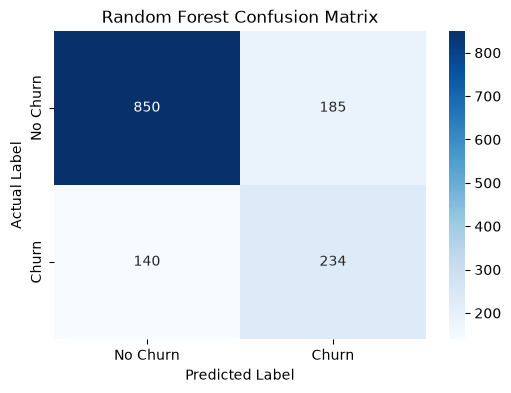

In [192]:
from sklearn.metrics import confusion_matrix
# Generate confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf,annot=True,fmt="d",cmap="Blues",xticklabels=["No Churn", "Churn"],yticklabels=["No Churn", "Churn"])
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### Observation
The confusion matrix shows that the Random Forest model correctly classified:

- 850 non-churn customers.
- 234 churn customers.

However, the model incorrectly classified 185 non-churn customers as churn and failed to identify 140 actual churn customers.

The results indicate that the model performs better in identifying non-churn customers than churn customers.

## 21. XGBoost Classifier

XGBoost (Extreme Gradient Boosting) is an ensemble learning algorithm based on gradient boosting.

It builds decision trees sequentially, where each new tree attempts to correct the errors made by previous trees.

In this project, XGBoost is used as the second classification model to predict customer churn.

The `scale_pos_weight` parameter is used to handle class imbalance by assigning greater importance to the minority class.

In [193]:
from xgboost import XGBClassifier

## 22. Handling Class Imbalance in XGBoost

The target variable contains more non-churn customers than churn customers.

The `scale_pos_weight` parameter is used to balance the importance of positive and negative classes during model training.

It is calculated as the ratio of the number of negative class samples to the number of positive class samples in the training dataset.

In [194]:
# Calculate scale_pos_weight
scale_pos_weight = ((y_train == 0).sum() / (y_train == 1).sum())
print("Scale Pos Weight:", scale_pos_weight)

Scale Pos Weight: 2.768561872909699


## 23. Creating the XGBoost Model Pipeline
An XGBoost classifier is created and combined with the preprocessing pipeline.

The model uses the `scale_pos_weight` parameter to handle class imbalance and the `random_state` parameter to ensure reproducibility.

In [195]:
# Create XGBoost pipeline
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

## 24. Training the XGBoost Model
The XGBoost classifier is trained using the training dataset.
During training, the model learns patterns and relationships between customer features and churn status.

The preprocessing pipeline transforms the input features before they are passed to the classifier for training.

In [196]:
# Train the XGBoost model
xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [197]:
print("XGBoost model trained successfully!")

XGBoost model trained successfully!


## 25. Making Predictions Using XGBoost
After training the XGBoost model, predictions are generated using the testing dataset.

The predicted class labels and churn probabilities will be used to evaluate the model's performance.

In [198]:
# Generate predictions on testing data
y_pred_xgb = xgb_model.predict(X_test)

In [199]:
# Generate churn probabilities
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

## 26. XGBoost Model Evaluation
The performance of the XGBoost classifier is evaluated using multiple classification metrics.

- Accuracy measures the overall proportion of correct predictions.
- Precision measures the correctness of predicted churn customers.
- Recall measures the proportion of actual churn customers correctly identified.
- F1-Score represents the balance between precision and recall.
- ROC-AUC measures the model's ability to distinguish between churn and non-churn customers.

In [200]:
# Calculate XGBoost evaluation metrics
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)
xgb_roc_auc = roc_auc_score(y_test, y_prob_xgb)

print("XGBoost Evaluation")
print("------------------")
print("Accuracy:", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall:", xgb_recall)
print("F1-Score:", xgb_f1)
print("ROC-AUC:", xgb_roc_auc)

XGBoost Evaluation
------------------
Accuracy: 0.7480482611781405
Precision: 0.5165794066317626
Recall: 0.7914438502673797
F1-Score: 0.6251319957761352
ROC-AUC: 0.8447531581802681


In [201]:
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.91      0.73      0.81      1035
       Churn       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



## 27. XGBoost Confusion Matrix
The confusion matrix is used to evaluate the classification performance of the XGBoost model.

It compares the actual target values with the predicted values and identifies correct and incorrect classifications for both churn and non-churn customers.

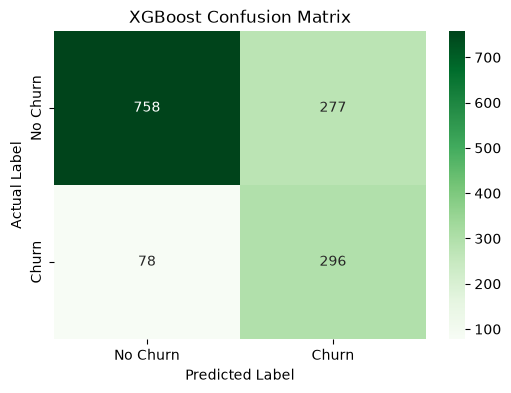

In [202]:
# Generate confusion matrix for XGBoost
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_xgb,annot=True,fmt="d",cmap="Greens",xticklabels=["No Churn", "Churn"],yticklabels=["No Churn", "Churn"])

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

## 28. ROC Curve Comparison
The Receiver Operating Characteristic (ROC) curve evaluates the performance of classification models at different probability thresholds.

- True Positive Rate (TPR): The proportion of actual churn customers correctly identified.
- False Positive Rate (FPR): The proportion of non-churn customers incorrectly identified as churn.

The ROC curve plots the True Positive Rate against the False Positive Rate.

The Area Under the Curve (AUC) represents the model's ability to distinguish between the two classes. A higher ROC-AUC score indicates better classification performance.

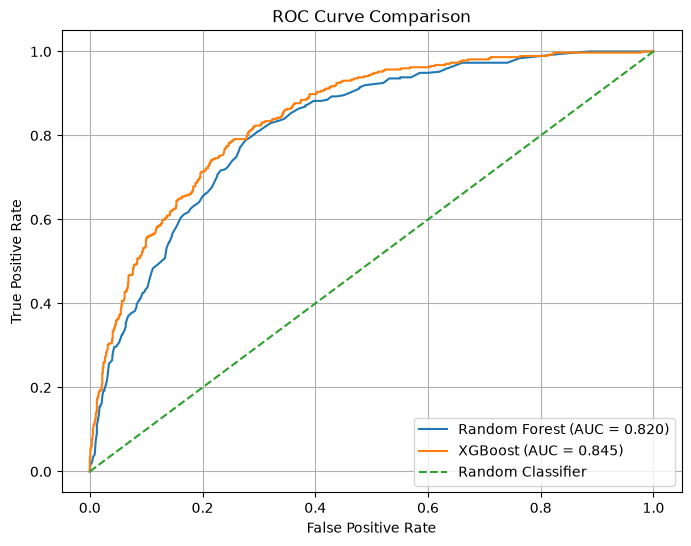

In [203]:
from sklearn.metrics import roc_curve
# Calculate ROC curve for Random Forest
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_prob_rf)

# Calculate ROC curve for XGBoost
fpr_xgb, tpr_xgb, thresholds_xgb = roc_curve(y_test, y_prob_xgb)

# Plot ROC curves
plt.figure(figsize=(8, 6))
plt.plot(fpr_rf,tpr_rf,label=f"Random Forest (AUC = {rf_roc_auc:.3f})")
plt.plot(fpr_xgb,tpr_xgb,label=f"XGBoost (AUC = {xgb_roc_auc:.3f})")

# Random classifier baseline
plt.plot([0, 1],[0, 1],linestyle="--",label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

In [204]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [205]:
# Create stratified 5-fold cross-validation
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [206]:
# Evaluate Random Forest using 5-fold cross-validation
rf_cv_scores = cross_val_score(rf_model,X_train,y_train,cv=cv,scoring="roc_auc",n_jobs=1)

print("Random Forest Cross-Validation Scores:", rf_cv_scores)
print("Mean ROC-AUC:", rf_cv_scores.mean())
print("Standard Deviation:", rf_cv_scores.std())

Random Forest Cross-Validation Scores: [0.81518104 0.80461845 0.82666861 0.82046031 0.84412775]
Mean ROC-AUC: 0.8222112308305372
Standard Deviation: 0.013131617669212123


In [207]:
# Evaluate XGBoost using 5-fold cross-validation
xgb_cv_scores = cross_val_score(xgb_model,X_train,y_train,cv=cv,scoring="roc_auc",n_jobs=1)

print("XGBoost Cross-Validation Scores:", xgb_cv_scores)
print("Mean ROC-AUC:", xgb_cv_scores.mean())
print("Standard Deviation:", xgb_cv_scores.std())

XGBoost Cross-Validation Scores: [0.84212673 0.82947183 0.84405143 0.86297118 0.85748747]
Mean ROC-AUC: 0.847221728430141
Standard Deviation: 0.011870124404971297


## 30. Feature Importance Analysis
Feature importance helps identify which features contribute most to the model's predictions.

Both Random Forest and XGBoost provide feature importance scores. These scores are used to identify the top 10 features influencing customer churn prediction.

Higher importance scores indicate that a feature has a greater influence on the model's predictions.

In [208]:
# Extract feature names after preprocessing
rf_feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
# Extract feature importance scores
rf_importances = rf_model.named_steps["classifier"].feature_importances_
# Create a DataFrame
rf_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
})
# Sort features by importance
rf_importance_df = rf_importance_df.sort_values(by="Importance", ascending=False)
# Select Top 10 features
rf_top10 = rf_importance_df.head(10)
rf_top10

,Feature,Importance
3,num__TotalCharges,0.145060
1,num__tenure,0.126933
2,num__MonthlyCharges,0.124979
36,cat__Contract_Month-to-month,0.063191
18,cat__OnlineSecurity_No,0.038248
38,cat__Contract_Two year,0.036125
43,cat__PaymentMethod_Electronic check,0.031679
16,cat__InternetService_Fiber optic,0.030531
27,cat__TechSupport_No,0.028476
21,cat__OnlineBackup_No,0.017631


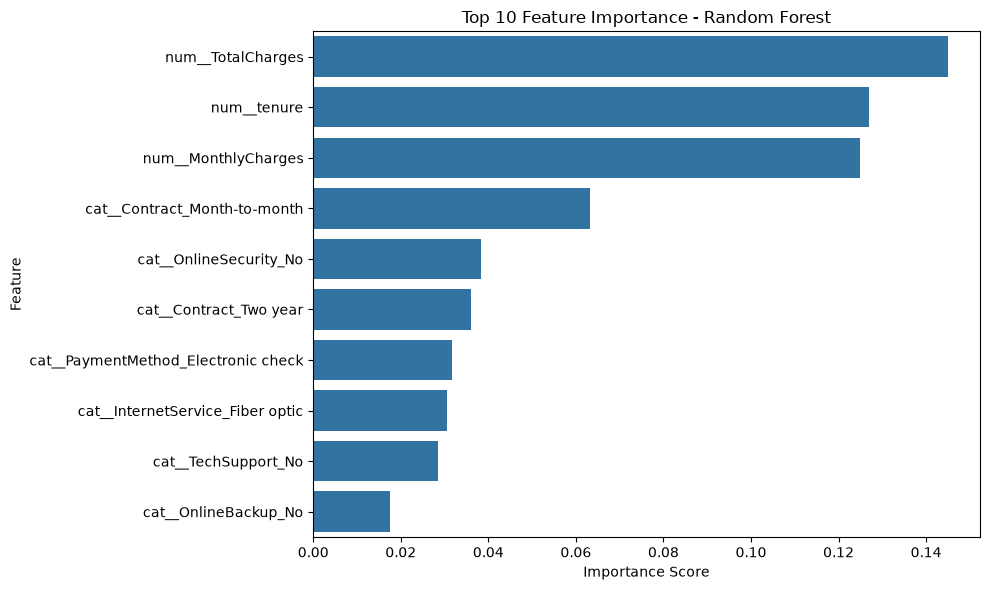

In [209]:
plt.figure(figsize=(10, 6))
sns.barplot(data=rf_top10,x="Importance",y="Feature")
plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [210]:
# Extract feature names after preprocessing
xgb_feature_names = xgb_model.named_steps["preprocessor"].get_feature_names_out()
# Extract feature importance scores
xgb_importances = xgb_model.named_steps["classifier"].feature_importances_
# Create a DataFrame
xgb_importance_df = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Importance": xgb_importances
})
# Sort features by importance
xgb_importance_df = xgb_importance_df.sort_values(by="Importance", ascending=False)
# Select Top 10 features
xgb_top10 = xgb_importance_df.head(10)
xgb_top10

,Feature,Importance
36,cat__Contract_Month-to-month,0.555514
16,cat__InternetService_Fiber optic,0.076271
18,cat__OnlineSecurity_No,0.062529
27,cat__TechSupport_No,0.061329
43,cat__PaymentMethod_Electronic check,0.028099
35,cat__StreamingMovies_Yes,0.027062
37,cat__Contract_One year,0.022596
38,cat__Contract_Two year,0.022290
17,cat__InternetService_No,0.020903
1,num__tenure,0.018413


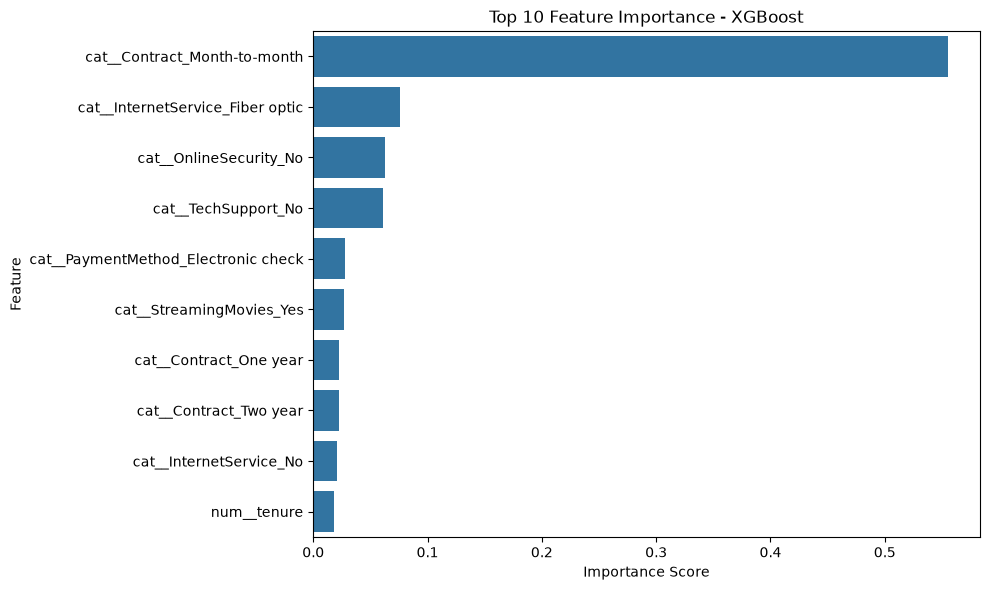

In [211]:
plt.figure(figsize=(10, 6))
sns.barplot(data=xgb_top10,x="Importance",y="Feature")
plt.title("Top 10 Feature Importance - XGBoost")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 31. Model Performance Comparison
In this section, the performance of Random Forest and XGBoost classifiers is compared using various evaluation metrics.

The comparison includes Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

These metrics provide a comprehensive evaluation of model performance, especially in the presence of class imbalance.

In [212]:
model_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Random Forest": [rf_accuracy,rf_precision,rf_recall,rf_f1,rf_roc_auc],
    "XGBoost": [xgb_accuracy,xgb_precision,xgb_recall,xgb_f1,xgb_roc_auc]
})
model_comparison

,Metric,Random Forest,XGBoost
0,Accuracy,0.769340,0.748048
1,Precision,0.558473,0.516579
2,Recall,0.625668,0.791444
3,F1-Score,0.590164,0.625132
4,ROC-AUC,0.819789,0.844753


## 32. Model Performance Visualization
The performance of Random Forest and XGBoost is visualized using a grouped bar chart.

This visualization allows a direct comparison of the evaluation metrics of both models and helps identify their relative strengths and weaknesses.

<Figure size 1000x600 with 0 Axes>

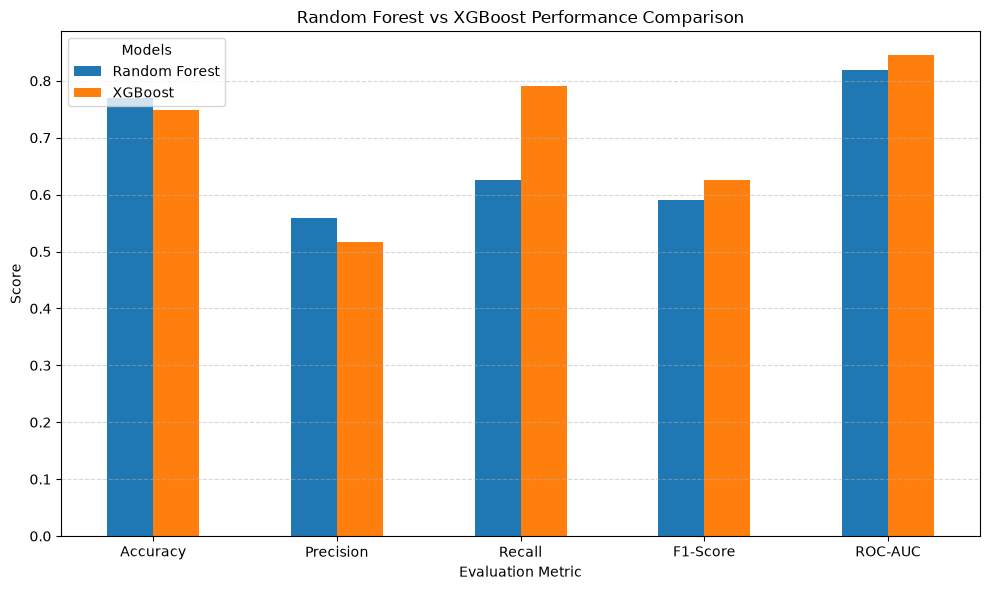

In [213]:
plt.figure(figsize=(10, 6))
model_comparison.set_index("Metric").plot(kind="bar",figsize=(10, 6))

plt.title("Random Forest vs XGBoost Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.xticks(rotation=0)
plt.legend(title="Models")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 33. Conclusion
This project focused on predicting customer churn using the Telco Customer Churn dataset. The dataset was analyzed, cleaned, and preprocessed before training machine learning classification models.

Random Forest and XGBoost classifiers were implemented using preprocessing pipelines. The class imbalance problem was addressed using class weights in Random Forest and scale_pos_weight in XGBoost.

Both models were evaluated using Accuracy, Precision, Recall, F1-Score, ROC-AUC, Confusion Matrices, ROC Curves, and Stratified Cross-Validation.

Feature importance analysis was performed to identify the key factors influencing customer churn predictions.

The results demonstrate the effectiveness of machine learning techniques in identifying customers who are likely to leave a service. These predictions can help businesses develop targeted customer retention strategies, improve customer satisfaction, and reduce customer loss.

Overall, this project provided practical experience in data preprocessing, handling imbalanced datasets, model training, evaluation, and interpretation of machine learning results.